<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/Fig1K_2E_healthy_vs_pcp_expression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
!pip install scanpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 181.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.5/73.5 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 224.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 26.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.8/91.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2

In [ ]:
import scanpy as sc

# Loading PCP data

In [ ]:
#import PCP object
pcp = sc.read("/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_2026_06_17.h5ad")
pcp

KeyboardInterrupt: 

#epi vs stem degs

In [ ]:
epi_stem = pcp[pcp.obs["broad_cluster"].isin(["Stem-like cells", "Epithelial cells"])]
epi_stem

Incorporating healthy data

In [ ]:
healthy = sc.read("/content/drive/MyDrive/pituitary_tumor_atlas/Unstructured/healthy_scanvi_2026_05_01.h5ad")
healthy

/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 203720 × 39055
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'GEO_x', 'assay', 'orig_index', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'GEO_y', 'Name', 'Conditions', 'Normal', 'Sorted', 'Author', 'Age', 'Sex_numeric', 'Sex', 'Comp_sex', 'Age_numeric', 'Split sample', '10X version', 'Modality', 'published', 'species', 'pseudoaligned', 'passed_qc', 'filtering_junk', 'median_cellassign_prob', 'most_recent_workflow', 'Core', 'n_cells', 'Notes:', 'processed_atac', 'passed_qc_tcc', 'tcc_pseudobulked', 'processed_atac.1', 'Internal_ID', 'DOI', 'Tumor_pta', 'Ethnicity', 'Symptom', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'Comorbidity'

In [ ]:
#print number of samples
#value counts on 'Internal_ID'
healthy.obs['Author'].value_counts()

Author
Zhang et al. (2026)     127015
Zhang et al. (2022)      62353
Asuzu et al., (2022)      8651
Yan et al., (2024)        5701
Name: count, dtype: int64

In [ ]:
healthy = healthy[healthy.obs["new_cell_type"]!="other"]

In [ ]:

sc.pl.dotplot(healthy,var_names=["S100A8","S100A9"], groupby='new_cell_type')

#merge

In [ ]:
pcp.obs["cell_type"] = "PCP_" + pcp.obs["broad_cluster"].astype(str)
healthy.obs["cell_type"] = "Healthy_" + healthy.obs["new_cell_type"].astype(str)

/tmp/ipykernel_1506/1281109909.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  healthy.obs["cell_type"] = "Healthy_" + healthy.obs["new_cell_type"].astype(str)


In [ ]:
import anndata as ad

# Merge the objects
merged_adata = ad.concat(
    [healthy, pcp],
    join="outer",
    label="dataset_origin",   # Creates a new column in .obs to track the source
    keys=["healthy", "pcp"]   # The labels assigned to cells from each respective object
)

/tmp/ipykernel_1506/106215553.py:4: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  merged_adata = ad.concat(


In [ ]:
healthy

AnnData object with n_obs × n_vars = 203005 × 39055
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'GEO_x', 'assay', 'orig_index', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'GEO_y', 'Name', 'Conditions', 'Normal', 'Sorted', 'Author', 'Age', 'Sex_numeric', 'Sex', 'Comp_sex', 'Age_numeric', 'Split sample', '10X version', 'Modality', 'published', 'species', 'pseudoaligned', 'passed_qc', 'filtering_junk', 'median_cellassign_prob', 'most_recent_workflow', 'Core', 'n_cells', 'Notes:', 'processed_atac', 'passed_qc_tcc', 'tcc_pseudobulked', 'processed_atac.1', 'Internal_ID', 'DOI', 'Tumor_pta', 'Ethnicity', 'Symptom', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'Comorbidity'

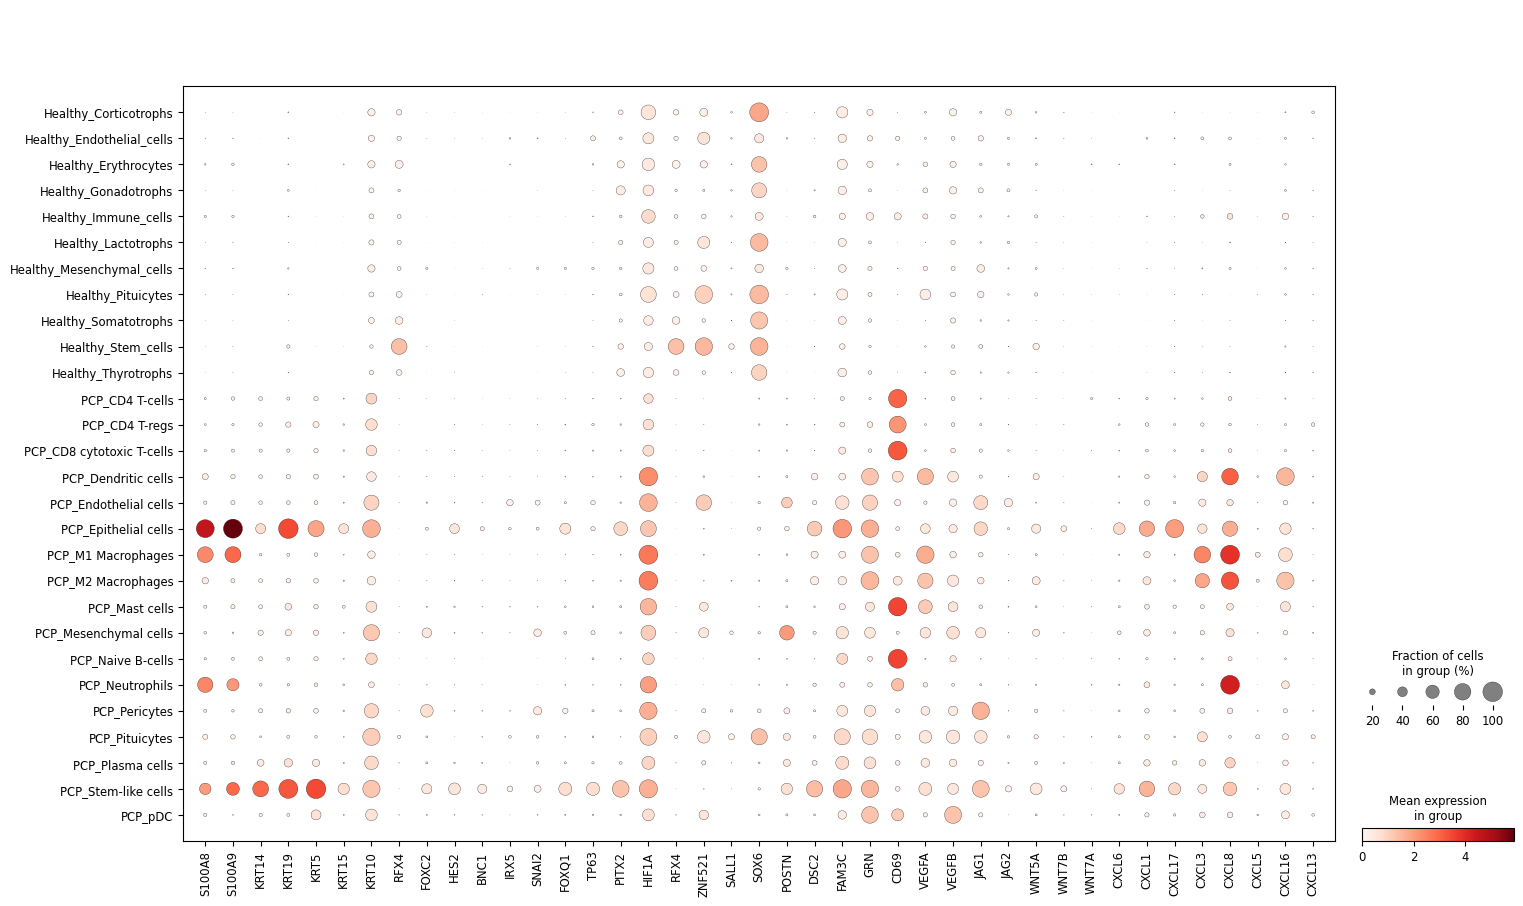

In [ ]:
sc.pl.dotplot(merged_adata, var_names=["S100A8","S100A9", "KRT14", "KRT19", "KRT5", "KRT15", "KRT17" and "KRT10",

                                       "RFX4","FOXC2", "HES2",  "BNC1", "IRX5", "SNAI2", #"FOXE2",
                                       "FOXQ1", "TP63","PITX2","HIF1A","RFX4","ZNF521","SALL1","SOX6",
                                       "POSTN", "DSC2", "FAM3C", "GRN", "CD69", "VEGFA","VEGFB", "JAG1","JAG2", "WNT5A", "WNT7B",# "WNT8A",
                                       "WNT7A",
                                       "CXCL6", "CXCL1", "CXCL17", "CXCL3", "CXCL8", "CXCL5", "CXCL16", "CXCL13",

                                       ], groupby='cell_type',swap_axes=False)




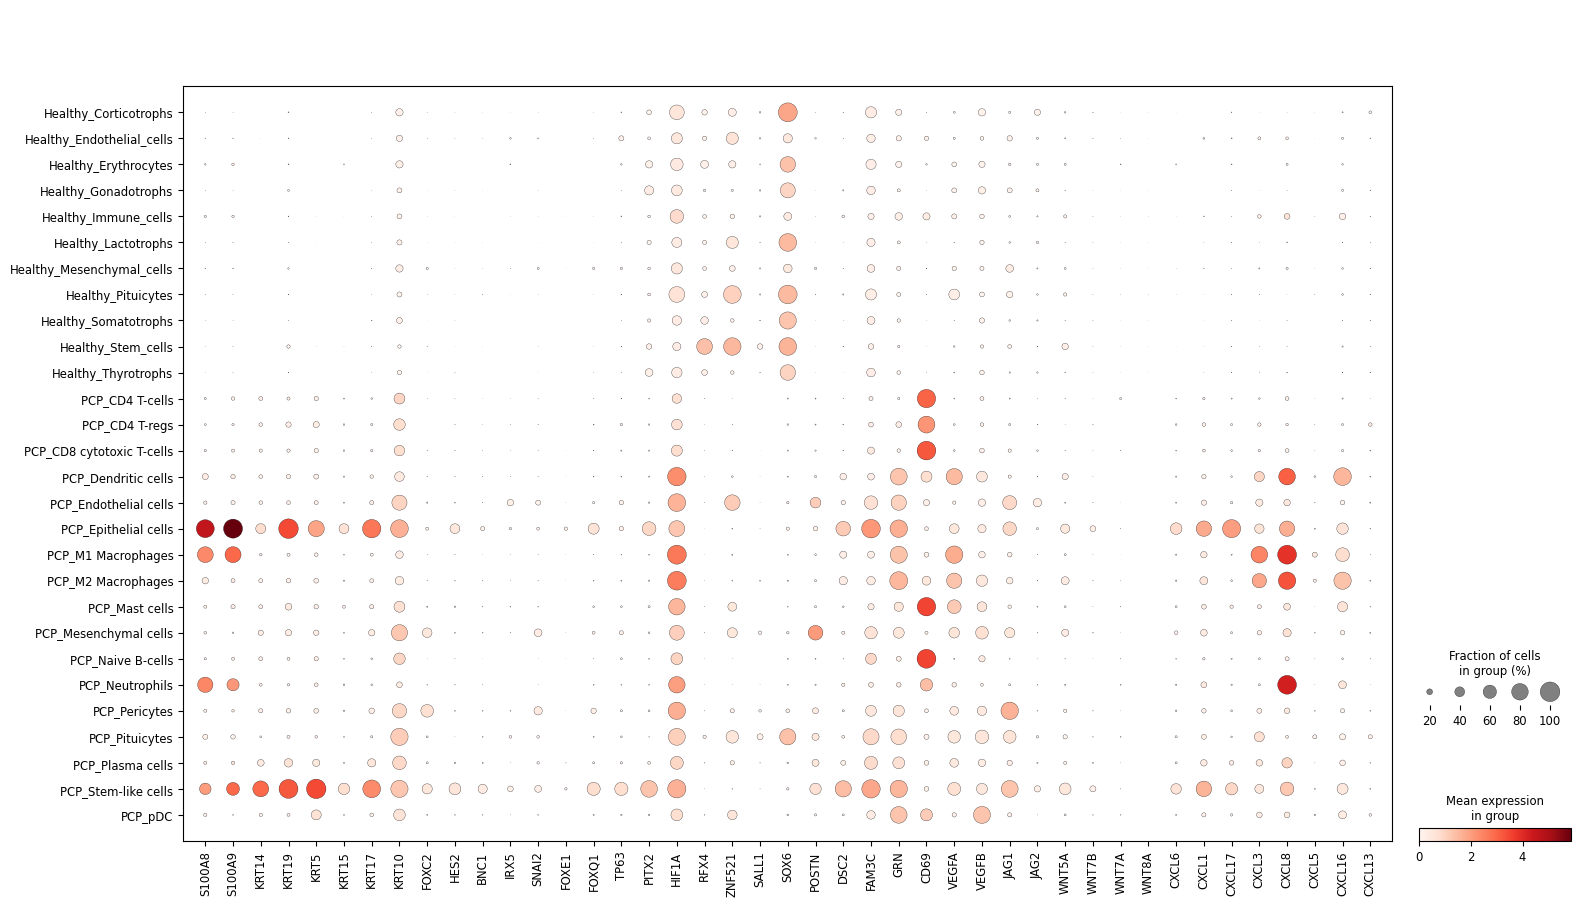

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Define your variable names correctly in a clean list
var_names = [
    "S100A8", "S100A9", "KRT14", "KRT19", "KRT5", "KRT15", "KRT17", "KRT10",
    "FOXC2", "HES2", "BNC1", "IRX5", "SNAI2","FOXE1",
    "FOXQ1", "TP63", "PITX2",
    "HIF1A", "RFX4", "ZNF521", "SALL1", "SOX6", "POSTN", "DSC2", "FAM3C",
    "GRN", "CD69", "VEGFA", "VEGFB", "JAG1", "JAG2", "WNT5A", "WNT7B", "WNT7A", "WNT8A",
    "CXCL6", "CXCL1", "CXCL17", "CXCL3", "CXCL8", "CXCL5", "CXCL16", "CXCL13"
]

# 2. Generate the dotplot with show=False so we can manipulate the figure
dp = sc.pl.dotplot(
    merged_adata,
    var_names=var_names,
    groupby='cell_type',
    swap_axes=False,
    show=False
)

# 3. Save the figure with 800 DPI
# bbox_inches='tight' ensures labels don't get cut off
plt.savefig("/content/drive/MyDrive/human_pcp/dotplot_high_res_all.png", dpi=800, bbox_inches='tight')
#svg
plt.savefig("/content/drive/MyDrive/human_pcp/dotplot_high_res_all.svg", bbox_inches='tight')

# Optional: Show the plot in your notebook/IDE after saving
plt.show()

In [ ]:
subset = merged_adata[merged_adata.obs["cell_type"].isin(["PCP_Stem-like cells","Healthy_Stem_cells","PCP_Epithelial cells"])]
subset

View of AnnData object with n_obs × n_vars = 41862 × 39055
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'SRA_ID', 'GEO_x', 'assay', 'orig_index', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'GEO_y', 'Name', 'Conditions', 'Normal', 'Sorted', 'Author', 'Age', 'Sex_numeric', 'Sex', 'Comp_sex', 'Age_numeric', 'Split sample', '10X version', 'Modality', 'published', 'species', 'pseudoaligned', 'passed_qc', 'filtering_junk', 'median_cellassign_prob', 'most_recent_workflow', 'Core', 'n_cells', 'Notes:', 'processed_atac', 'passed_qc_tcc', 'tcc_pseudobulked', 'processed_atac.1', 'Internal_ID', 'DOI', 'Tumor_pta', 'Ethnicity', 'Symptom', 'Lineage', 'Cell type', 'Subtype', 'Secretion', 'Disease', 'Comor

In [ ]:
subset.obs["cell_type"].value_counts()

cell_type
Healthy_Stem_cells      21718
PCP_Stem-like cells     11831
PCP_Epithelial cells     8313
Name: count, dtype: int64

# Figure 2E

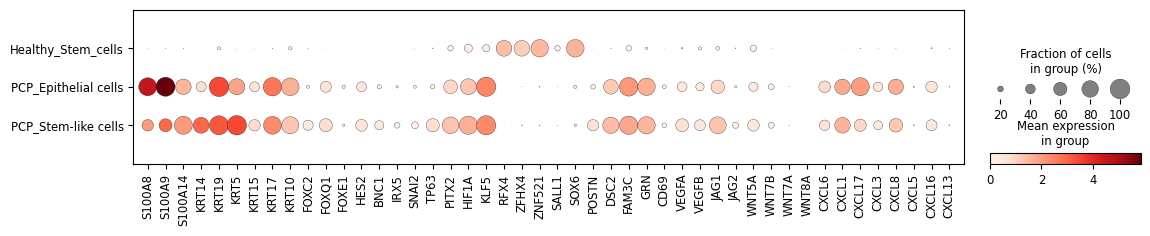

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Define your variable names correctly in a clean list
var_names = [
    "S100A8", "S100A9", "S100A14", "KRT14", "KRT19", "KRT5", "KRT15", "KRT17", "KRT10",
    "FOXC2", "FOXQ1", "FOXE1", "HES2", "BNC1", "IRX5", "SNAI2", "TP63", "PITX2",
    "HIF1A", "KLF5",
    "RFX4", "ZFHX4", "ZNF521", "SALL1", "SOX6", "POSTN", "DSC2", "FAM3C",
    "GRN", "CD69", "VEGFA", "VEGFB", "JAG1", "JAG2", "WNT5A", "WNT7B", "WNT7A", "WNT8A",
    "CXCL6", "CXCL1", "CXCL17", "CXCL3", "CXCL8", "CXCL5", "CXCL16", "CXCL13"
]

# 2. Generate the dotplot with show=False so we can manipulate the figure
dp = sc.pl.dotplot(
    subset,
    var_names=var_names,
    groupby='cell_type',
    swap_axes=False,
    show=False,
    figsize=(13, 2)
)

# 3. Save the figure with 800 DPI
# bbox_inches='tight' ensures labels don't get cut off
plt.savefig("/content/drive/MyDrive/human_pcp/dotplot_high_res.png", dpi=800, bbox_inches='tight')
plt.savefig("/content/drive/MyDrive/human_pcp/dotplot_high_res.svg",  bbox_inches='tight')

# Optional: Show the plot in your notebook/IDE after saving
plt.show()

# Figure 1K

In [ ]:
pcp_subset = pcp[pcp.obs["broad_cluster"].isin(["Stem-like cells", "Epithelial cells"])]
pcp_subset

View of AnnData object with n_obs × n_vars = 20144 × 20000
    obs: '0', 'n_genes', 'n_counts', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_malat', 'log1p_total_counts_malat', 'pct_counts_malat', 'doublet_score', 'predicted_doublet', 'size_factor', 'assignments', 'dataset', 'batch', '_scvi_batch', '_scvi_labels', 'leiden_scVI', '_scvi_raw_norm_scaling', 'broad_cluster', 'Specific_cluster', 'patient', 'cell_type'
    var: '0', 'feature_types', 'mt', 'ribo', 'malat', 'n_cells_by_counts-0', 'mean_counts-0', 'log1p_mean_counts-0', 'pct_dropout_by_counts-0', 'total_counts-0', 'log1p_total_counts-0', 'n_cells_by_counts-1', 'mean_counts-1', 'log1p_mean_counts-1', 'pct_dropout_by_counts-1', 'total_counts-1', 'log1p_total_counts-1', 'n_cells_by_counts-2', 'mean_counts-2', 'log1p_mean_

/usr/local/lib/python3.13/dist-packages/scanpy/_utils/__init__.py:471: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata._sanitize()


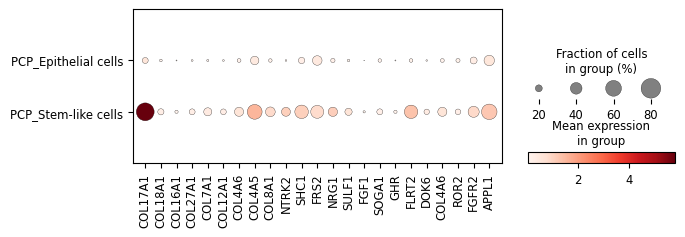

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Define your variable names correctly in a clean list
var_names = [
   "COL17A1","COL18A1","COL16A1","COL27A1","COL7A1","COL12A1","COL4A6","COL4A5","COL8A1",
   "NTRK2","SHC1","FRS2","NRG1","SULF1","FGF1","SOGA1", "GHR","FLRT2","DOK6","COL4A6","ROR2","FGFR2","APPL1"
]

# 2. Generate the dotplot with show=False so we can manipulate the figure
dp = sc.pl.dotplot(
    pcp_subset,
    var_names=var_names,
    groupby='cell_type',
    swap_axes=False,
    show=False,
    figsize=(7, 2)
)

# 3. Save the figure with 800 DPI
# bbox_inches='tight' ensures labels don't get cut off
plt.savefig("/content/drive/MyDrive/human_pcp/collagens_res.png", dpi=800, bbox_inches='tight')
plt.savefig("/content/drive/MyDrive/human_pcp/collagens.svg",  bbox_inches='tight')

# Optional: Show the plot in your notebook/IDE after saving
plt.show()

In [ ]:
pip freeze

absl-py==1.4.0
accelerate==1.14.0
aiofiles==25.1.0
aiohappyeyeballs==2.7.1
aiohttp==3.14.3
aiosignal==1.4.0
altair==5.5.0
anndata==0.13.3.post0
annotated-doc==0.0.5
annotated-types==0.8.0
anyio==4.14.2
anywidget==0.9.21
apsw==3.53.4.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
array-api-compat==1.15.0
array_record==0.8.3
arrow==1.4.0
attrs==26.1.0
audioop-lts==0.2.2
audioread==3.1.0
backcall==0.2.0
beartype==0.22.9
beautifulsoup4==4.13.5
betterproto==2.0.0b7
bleach==6.4.0
blinker==1.7.0
blis==1.3.3
catalogue==2.0.10
certifi==2026.7.22
cffi==2.1.1
charset-normalizer==3.4.9
chex==0.1.90
click==8.5.0
cloudpathlib==0.25.0
cloudpickle==3.1.2
confection==1.3.3
contourpy==1.3.3
cryptography==50.0.1
cycler==0.12.1
cymem==2.0.13
datasets==4.8.5
dbus-python==1.3.2
debugpy==1.8.15
decorator==5.3.1
defusedxml==0.7.1
dill==0.4.1
distrax==0.1.5
distro==1.9.0
dm-tree==0.1.10
docstring_parser==0.18.0
donfig==0.8.1.post1
einops==0.8.2
en_core_web_sm @ https://github.com/explosion/spacy-models/rel